# Tahap 16 — E2: intervensi input dan E1 pada model baru yang sama

**Analisis tambahan eksploratori**, disiapkan setelah E0/E1 lama diketahui.
Status preregistrasi, hasil lama, dan manuskrip tidak diubah.

**Run All notebook ini oleh pengguna dapat melakukan training ulang:** NewHandPD
spiral, BiGRU/BiMamba-2, seed 0/1/2, lima fold subjek = **30 model** bila tidak ada
checkpoint yang cocok. Agen hanya membangun notebook ini, tidak menjalankannya.
Tiga seed merupakan pilihan minimum praktis, bukan jaminan power atau reproduksi
seluruh hasil E1 sepuluh seed. Tidak ada pencarian hyperparameter.

Checkpoint baru menyimpan bobot, normalizer, split aktual, konfigurasi, hash data
dan kode. E1 dan E2 menggunakan logit, attention dan model yang sama. Data S3/S5
tidak ditimpa. Checkpoint dan hasil per-fold dapat dipakai ulang bila spec cocok.

Perbaikan teknis setelah run awal terhenti pada pemeriksaan anchor: baseline,
anchor dan setiap input bermasker sekarang memakai **forward batch 1**. Toleransi
anchor tetap, dan pemeriksaan dilakukan sebelum/sesudah intervensi. Checkpoint
training tetap kompatibel; cache evaluasi protokol lama tidak dipakai ulang.

**Primary E2:** apakah penghapusan input yang ditonjolkan attention mengubah logit
lebih besar daripada ranking acak? **Secondary:** apakah penghapusan tersebut
mengurangi dukungan terhadap kelas asli? Attention tidak bertanda; pengaruh input
dan arah dukungan kelas tidak disamakan. Hasil mengukur respons model terhadap
masker, bukan kausalitas fisiologis. Petunjuk: `scripts/E2.md`.

Pilih kernel Skripsi (.venv), baca sel konfigurasi, lalu Restart Kernel and Run All.


In [1]:
from pathlib import Path
import sys, json, pickle, platform
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/audit_e2.py").is_file()), None)
if ROOT is None: raise FileNotFoundError("jalankan dari root proyek/notebooks")
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from sklearn.model_selection import StratifiedGroupKFold
from IPython.display import display
from newhandpd import muat_cache_bisp
from artefak import simpan_atomik
from audit_e0_e1 import (
    AlignmentError, PreparedCohort, STATUS_ANALISIS, E1_METRICS,
    cache_manifest, file_sha256, subject_scores, e1_pairs, e1_subject_summary,
    e1_subject_relations, e1_sensitivity, bootstrap_subject_table,
)
from e2_checkpoints import fold_spec, spec_digest, get_fold_model, FrozenPredictor
from audit_e2 import (evaluate_record, e2_record_scores, e2_subject_scores,
                      E2_METRICS, join_e1_e2, JOINT_METRICS, joint_subject_sensitivity)
from viz import pasang_gaya, WARNA, rapikan
pasang_gaya()

## Pemeriksaan sintetis sebelum training

Ketika pengguna menjalankan sel ini, pemeriksaan CPU memakai model linear buatan
untuk masker, donor, AOPC, konteks batch/anchor dan identitas E1/E2. Ia tidak membaca data penelitian
atau melatih model. Kegagalan menghentikan notebook sebelum training yang mahal.
Pemeriksaan numerik ini belum dijalankan oleh agen saat menyiapkan notebook.


In [2]:
import unittest
suite = unittest.defaultTestLoader.discover(str(ROOT / "tests"), pattern="test_audit_e2.py")
result = unittest.TextTestRunner(verbosity=2).run(suite)
if result.testsRun == 0 or not result.wasSuccessful():
    raise RuntimeError("pemeriksaan sintetis E2 gagal; training belum dimulai")

test_anchor_after_detects_model_state_drift (test_audit_e2.E2Tests.test_anchor_after_detects_model_state_drift) ... ok
test_anchor_detects_different_original_output (test_audit_e2.E2Tests.test_anchor_detects_different_original_output) ... ok
test_batch_sensitive_predictor_uses_singletons_for_every_forward (test_audit_e2.E2Tests.test_batch_sensitive_predictor_uses_singletons_for_every_forward) ... ok
test_donor_plan_tracks_contiguous_training_blocks (test_audit_e2.E2Tests.test_donor_plan_tracks_contiguous_training_blocks) ... ok
test_input_can_influence_output_while_opposing_original_class (test_audit_e2.E2Tests.test_input_can_influence_output_while_opposing_original_class) ... ok
test_join_requires_matching_checkpoint_and_original_logit (test_audit_e2.E2Tests.test_join_requires_matching_checkpoint_and_original_logit) ... ok
test_larger_batch_rejected_before_any_forward (test_audit_e2.E2Tests.test_larger_batch_rejected_before_any_forward) ... ok
test_mask_preserves_length_tail_and_origi

## 1. Konfigurasi yang ditetapkan sebelum E2 dijalankan

Ubah parameter melalui builder `.py`, lalu bangun ulang notebook. Pilihan masker,
budget, jumlah seed dan kontrol berikut dicatat sebelum hasil E2 diketahui.
Konfigurasi training mengikuti pipeline lama. Jangan memperlakukan AUROC tiga
seed baru sebagai reproduksi headline sepuluh seed, atau menambah seed/ambang
berdasarkan apakah hasil yang diinginkan telah muncul.


In [3]:
ARMS = ("gru", "mamba2")
SEEDS = (0, 1, 2)
PATCH, FS = 7, 100.
MODEL_CONFIG = dict(in_channels=6, d_model=128, patch_size=PATCH, n_layers=3,
                    dropout=.30, d_dir=64, pooling="attention")
TRAINING_CONFIG = dict(epochs=35, batch_size=8, lr=3e-4)
ALLOW_TRAINING_IF_MISSING = True  # Run All dapat melatih 30 model baru.
FRACTIONS = (.05, .10, .20, .30)
RANDOM_REPEATS, DONOR_REPEATS = 20, 5
DONOR_BLOCK_PATCHES = 32  # blok kontigu 2,24 detik; semua kanal dipindahkan bersama
PERTURBATION_BATCH = 1  # wajib: baseline/anchor/intervensi memakai forward batch yang sama
INTERVENTION_SEED = 1600
N_BOOT, BOOT_SEED, CONFIDENCE = 5000, 1601, .95
EPS_PROB, EPS_LOGIT = (.01, .02, .05), (None, .1, .25, .5)
if PERTURBATION_BATCH != 1:
    raise ValueError("E2 memerlukan PERTURBATION_BATCH=1; training belum dimulai")
CACHE = ROOT / "data/cache/newhandpd_spiral_fs100.npz"
if not CACHE.is_file(): raise FileNotFoundError(CACHE)
if not torch.cuda.is_available():
    raise RuntimeError("Notebook model BiMamba-2 ini memerlukan lingkungan CUDA proyek. Training belum dimulai.")
DEVICE = "cuda"
VERSIONS = {p: version(p) for p in ("numpy", "pandas", "scipy", "scikit-learn", "torch")}
for package in ("mamba-ssm", "causal-conv1d", "triton", "einops"):
    try: VERSIONS[package] = version(package)
    except PackageNotFoundError: VERSIONS[package] = "metadata_version_unavailable"
VERSIONS["cuda_runtime"] = str(torch.version.cuda)
records = cache_manifest(CACHE, "newhandpd", PATCH, FS)
recordings = muat_cache_bisp(CACHE)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
splits = list(splitter.split(np.zeros(len(records)), records.label, records.subject))
fold_actual = np.full(len(records), -1, int)
for fold, (train, test) in enumerate(splits):
    if set(records.subject.iloc[train]) & set(records.subject.iloc[test]):
        raise AlignmentError("subjek muncul di train dan test")
    fold_actual[test] = fold
records["fold_actual"] = fold_actual
if (fold_actual < 0).any(): raise AlignmentError("split tidak lengkap")
source_paths = [ROOT / p for p in (
    "src/audit_e2.py", "src/e2_checkpoints.py", "src/audit_e0_e1.py", "scripts/build_nb_16.py",
    "src/model.py", "src/training.py", "src/preprocessing.py", "src/newhandpd.py")]
inventory = pd.DataFrame([dict(path=str(p.relative_to(ROOT)), sha256_before=file_sha256(p))
                           for p in [CACHE, *source_paths]])
cache_hash = file_sha256(CACHE)
EVAL_SPEC = dict(evaluation_protocol_version=2, cohort="newhandpd", patch=PATCH, fs=FS, arms=ARMS, seeds=SEEDS,
    model_config=MODEL_CONFIG, training_config=TRAINING_CONFIG,
    fractions=FRACTIONS, random_repeats=RANDOM_REPEATS, donor_repeats=DONOR_REPEATS,
    donor_block_patches=DONOR_BLOCK_PATCHES, forward_batch_size=PERTURBATION_BATCH,
    unmasked_check=dict(phases=["before", "after"], atol=1e-4, rtol=1e-4),
    intervention_seed=INTERVENTION_SEED, cache_sha256=cache_hash,
    analysis_sources={p: file_sha256(ROOT / p) for p in ("src/audit_e2.py", "src/audit_e0_e1.py")},
    jsd=dict(kind="divergence", log_base=2, input="nonnegative alpha normalized to sum 1", range=[0,1]),
    primary="normalized deletion AOPC abs_delta_logit: alpha_top - random",
    secondary="signed_margin_drop and predicted_class_prob_drop")
evaluation_id = spec_digest(EVAL_SPEC)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUT, FIG = ROOT / "results/e2" / RUN_ID, ROOT / "figures/e2" / RUN_ID
OUT.mkdir(parents=True, exist_ok=False); FIG.mkdir(parents=True, exist_ok=False)
inventory.to_csv(OUT / "input_inventory.csv", index=False)
records.to_csv(OUT / "record_manifest.csv", index=False)
manifest = dict(run_id=RUN_ID, evaluation_id=evaluation_id, evaluation_spec=EVAL_SPEC,
    status=STATUS_ANALISIS, old_preregistration_changed=False, versions=VERSIONS,
    python=platform.python_version(), device=torch.cuda.get_device_name(),
    completion_status="started", analysis_design_date="2026-10-12",
    technical_revision="batch 1 dan anchor sebelum/sesudah; perbaikan setelah run awal terhenti, toleransi tetap",
    inference="CI subjek bersyarat pada checkpoint, split, seed dan library intervensi; tidak mencakup training/split baru",
    masker_limit="intervensi pada representasi model; zero/donor tidak dijamin in-distribution")
(OUT / "analysis_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Maksimum model yang perlu dilatih:", len(ARMS)*len(SEEDS)*len(splits))
print("Checkpoint baru: checkpoints/e2/<training-spec-id>/model.pt")
print("Inferensi: forward batch 1, anchor sebelum/sesudah; checkpoint cocok dipakai ulang.")
print("Output:", OUT)
display(records[["idx", "record_id", "subject", "task", "fold_actual", "n_patches"]].head())

Maksimum model yang perlu dilatih: 30
Checkpoint baru: checkpoints/e2/<training-spec-id>/model.pt
Inferensi: forward batch 1, anchor sebelum/sesudah; checkpoint cocok dipakai ulang.
Output: /home/agribychaniago/Python Projects/Skripsi/results/e2/20261012T050124548170Z


,idx,record_id,subject,task,fold_actual,n_patches
0,0,newhandpd:H1:task0:seg0,H1,0,1,152
1,1,newhandpd:H10:task0:seg0,H10,0,1,168
2,2,newhandpd:H11:task0:seg0,H11,0,3,184
3,3,newhandpd:H12:task0:seg0,H12,0,4,208
4,4,newhandpd:H13:task0:seg0,H13,0,4,184


## 2. Model beku, masker dan kontrol

Untuk setiap fold, normalizer hanya fit pada train. Model/checkpoint disimpan
sebelum intervensi. Tidak ada training ulang untuk setiap budget/masker.

- **train_median:** patch normalized diganti nol, yang merepresentasikan median
  kanal training (bukan koordinat/sinyal mentah nol).
- **train_donor:** library lima background dari blok same-task 32 patch, dipilih
  hanya dari subjek training tanpa memakai label test. Semua enam kanal disalin
  bersama. Blok kontigu mempertahankan dependensi lokal, tetapi sambungan blok
  tetap dapat membuat artefak; rencana donor dan perubahan input dicatat.
- Ranking α tertinggi, α terendah, serta 20 ranking acak nested. Semua memakai
  jumlah patch dan library background yang sama. Tie diputus acak secara seeded.
  Kontrol acak dibagi seimbang atas lima background donor.

Intervensi mengganti input, lalu seluruh encoder/head dihitung ulang. T, grid dan
tail tidak berubah. Jumlah run mask, RMS perubahan input dan hash mask dilaporkan;
geometri mask tidak selalu sama antara ranking. Hasil tetap bersyarat pada masker.

Baseline/attention, anchor unmasked dan semua intervensi memakai batch 1 untuk
menghindari perbedaan konteks batching. Anchor diperiksa sebelum/sesudah; toleransi
tetap atol=rtol=1e-4. Inferensi bisa lebih lambat daripada batching. Perubahan ini
mengubah evaluation ID, bukan training ID: checkpoint cocok dimuat, sedangkan
cache intervensi protokol lama dihitung ulang. Semua artefak lama dipertahankan.


In [4]:
runs, all_curves, model_rows = {}, [], []
for arm in ARMS:
    for seed in SEEDS:
        run = dict(arsitektur=arm, seed=seed, logit_oof=np.full(len(records), np.nan),
                   peta=[], fold_oof=fold_actual.copy(), config={**MODEL_CONFIG, **TRAINING_CONFIG})
        for fold, (train, test) in enumerate(splits):
            spec = fold_spec(ROOT, cache_hash, records, train, test, arm, seed, fold,
                             MODEL_CONFIG, TRAINING_CONFIG, VERSIONS)
            model_id = spec_digest(spec)
            cache_dir = ROOT / "results/e2_cache" / evaluation_id / model_id
            fold_cache = cache_dir / "fold.pkl"
            cache_metadata = cache_dir / "fold_manifest.json"
            checkpoint = ROOT / "checkpoints/e2" / model_id / "model.pt"
            metadata = checkpoint.parent / "metadata.json"
            if fold_cache.exists():
                if not cache_metadata.is_file():
                    raise AlignmentError("cache evaluasi parsial tanpa manifest; periksa sebelum melanjutkan")
                cache_info = json.loads(cache_metadata.read_text())
                if (cache_info["evaluation_id"] != evaluation_id or cache_info["model_id"] != model_id
                        or cache_info["fold_cache_sha256"] != file_sha256(fold_cache)):
                    raise AlignmentError("identitas/hash cache evaluasi tidak cocok")
                payload = pickle.loads(fold_cache.read_bytes())
                if payload["evaluation_spec_json"] != json.dumps(EVAL_SPEC, sort_keys=True):
                    raise AlignmentError("spec cache evaluasi tidak cocok")
                if not checkpoint.is_file() or not metadata.is_file():
                    raise AlignmentError("cache evaluasi ada tetapi checkpoint/metadata hilang")
                meta = json.loads(metadata.read_text())
                checksum = file_sha256(checkpoint)
                if meta["spec"] != spec or meta["checkpoint_sha256"] != checksum or payload["checkpoint_sha256"] != checksum:
                    raise AlignmentError("checkpoint cache evaluasi tidak cocok")
                trained_now = False
                print(arm, seed, fold, "memakai cache evaluasi dan checkpoint terverifikasi")
            else:
                print(arm, seed, fold, "memuat/melatih checkpoint lalu mengevaluasi input")
                m, norm, info = get_fold_model(ROOT, spec, recordings, DEVICE, ALLOW_TRAINING_IF_MISSING)
                trained_now = info["trained_now"]
                donor_pool = {}
                for idx in train:
                    row = records.iloc[idx]
                    donor_pool.setdefault(int(row.task), []).append(
                        (int(idx), row.subject, norm.transform(recordings[idx].kanal)))
                maps, logits, fold_curves, plans = [], [], [], []
                for idx in test:
                    row = records.iloc[idx]
                    x = norm.transform(recordings[idx].kanal)
                    predictor = FrozenPredictor(m, DEVICE, len(x))
                    logit, alpha = predictor.original(x)
                    try:
                        curves, donor_plan = evaluate_record(predictor, x, alpha, logit,
                            donor_pool[int(row.task)], record_id=row.record_id,
                            random_seed=INTERVENTION_SEED, patch=PATCH, fractions=FRACTIONS,
                            random_repeats=RANDOM_REPEATS, donor_repeats=DONOR_REPEATS,
                            block_patches=DONOR_BLOCK_PATCHES, batch_size=PERTURBATION_BATCH)
                    except AlignmentError as error:
                        raise AlignmentError(
                            f"architecture={arm}, seed={seed}, fold={fold}, idx={int(idx)}, "
                            f"model_id={model_id}: {error}") from error
                    for key, value in dict(architecture=arm, seed=seed, fold=fold, model_id=model_id,
                        idx=int(idx), subject=row.subject, label=int(row.label), record_id=row.record_id).items():
                        curves[key] = value
                    fold_curves.append(curves)
                    maps.append(dict(idx=int(idx), subjek=row.subject, label=int(row.label), alpha=alpha,
                        logit=logit, model_id=model_id, seed=seed, arsitektur=arm,
                        fold=fold, tugas=int(row.task), fs=FS, patch=PATCH))
                    logits.append(logit)
                    plans.append(dict(idx=int(idx), record_id=row.record_id, donor_library=donor_plan))
                payload = dict(evaluation_spec_json=json.dumps(EVAL_SPEC, sort_keys=True),
                    checkpoint_sha256=info["checkpoint_sha256"], test_indices=list(map(int,test)),
                    logits=logits, maps=maps, curves=pd.concat(fold_curves, ignore_index=True),
                    donor_plans=plans)
                cache_dir.mkdir(parents=True, exist_ok=True)
                simpan_atomik(fold_cache, payload)
                temporary_manifest = cache_dir / "fold_manifest.json.tmp"
                temporary_manifest.write_text(json.dumps(dict(evaluation_id=evaluation_id,model_id=model_id,
                    fold_cache_sha256=file_sha256(fold_cache)),indent=2),encoding="utf-8")
                temporary_manifest.replace(cache_metadata)
                del predictor, m, norm, donor_pool
                torch.cuda.empty_cache()
            if payload["test_indices"] != list(map(int,test)):
                raise AlignmentError("test indices cache berbeda")
            run["logit_oof"][test] = payload["logits"]
            run["peta"].extend(payload["maps"])
            all_curves.append(payload["curves"])
            model_rows.append(dict(architecture=arm, seed=seed, fold=fold, model_id=model_id,
                checkpoint=str(checkpoint.relative_to(ROOT)), checkpoint_sha256=payload["checkpoint_sha256"],
                trained_now=trained_now, evaluation_cache=str(fold_cache.relative_to(ROOT))))
        if not np.isfinite(run["logit_oof"]).all() or {p["idx"] for p in run["peta"]} != set(records.idx):
            raise AlignmentError("OOF/peta model baru tidak lengkap")
        runs[(arm,seed)] = run
new_artifact = list(runs.values())
simpan_atomik(OUT / "joint_oof_maps.pkl", new_artifact)
model_inventory = pd.DataFrame(model_rows)
model_inventory.to_csv(OUT / "model_inventory.csv", index=False)
curves = pd.concat(all_curves, ignore_index=True)
curves.to_csv(OUT / "e2_curves_raw.csv", index=False)
display(model_inventory)
print("Model baru dilatih pada run ini:", int(model_inventory.trained_now.sum()))

gru 0 0 memuat/melatih checkpoint lalu mengevaluasi input


/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/selective_scan_interface.py:163: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/selective_scan_interface.py:239: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/triton/layer_norm.py:985: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/triton/layer_norm.py:1044: FutureWarning: `torch.cuda.amp.custom_bwd(args

gru 0 1 memuat/melatih checkpoint lalu mengevaluasi input
gru 0 2 memuat/melatih checkpoint lalu mengevaluasi input
gru 0 3 memuat/melatih checkpoint lalu mengevaluasi input
gru 0 4 memuat/melatih checkpoint lalu mengevaluasi input
    epoch   7/35  rugi=0.2556
    epoch  14/35  rugi=0.0033
    epoch  21/35  rugi=0.0009
    epoch  28/35  rugi=0.0008
    epoch  35/35  rugi=0.0007
gru 1 0 memuat/melatih checkpoint lalu mengevaluasi input
    epoch   7/35  rugi=0.3744
    epoch  14/35  rugi=0.0165
    epoch  21/35  rugi=0.0013
    epoch  28/35  rugi=0.0008
    epoch  35/35  rugi=0.0010
gru 1 1 memuat/melatih checkpoint lalu mengevaluasi input
    epoch   7/35  rugi=0.2596
    epoch  14/35  rugi=0.0250
    epoch  21/35  rugi=0.0016
    epoch  28/35  rugi=0.0011
    epoch  35/35  rugi=0.0010
gru 1 2 memuat/melatih checkpoint lalu mengevaluasi input
    epoch   7/35  rugi=0.3133
    epoch  14/35  rugi=0.0086
    epoch  21/35  rugi=0.0013
    epoch  28/35  rugi=0.0011
    epoch  35/35  rugi=0

,architecture,seed,fold,model_id,checkpoint,checkpoint_sha256,trained_now,evaluation_cache
0,gru,0,0,a21b89aaa6e4c9fc994ff5700a30d0344717847b4b1c35...,checkpoints/e2/a21b89aaa6e4c9fc994ff5700a30d03...,1883e5537750547dd6886450ed2fc75cbaeb3383fb0403...,False,results/e2_cache/c4b1d743f22d6b9bbbc5b2a2a8fcd...
1,gru,0,1,97d3e9e6c249f8a59062e502dd6b25246c97dc6ec3aa83...,checkpoints/e2/97d3e9e6c249f8a59062e502dd6b252...,acb96b167dd94cc012443dfb5e40c12b5817923151086f...,False,results/e2_cache/c4b1d743f22d6b9bbbc5b2a2a8fcd...
2,gru,0,2,7ab08ab0627be0fee82f26a9e957e1aee5cff50cba546b...,checkpoints/e2/7ab08ab0627be0fee82f26a9e957e1a...,bfbd9c70aa4ea4150bd533fe51394f3ec67866f6c1ea55...,False,results/e2_cache/c4b1d743f22d6b9bbbc5b2a2a8fcd...
3,gru,0,3,e6d55b14d28fb03d65bb33b6dc6bdb4acdc40f1fb96e87...,checkpoints/e2/e6d55b14d28fb03d65bb33b6dc6bdb4...,69ab7664f565b9e67fb5dd6134b6a2258551d191cae5ad...,False,results/e2_cache/c4b1d743f22d6b9bbbc5b2a2a8fcd...
4,gru,0,4,69f6b66cbdf190b77619175a484e72ca81914f935ec82b...,checkpoints/e2/69f6b66cbdf190b77619175a484e72c...,07ae607da48fc758b2f0e7dcfb9274e7882db478ca76d6...,True,results/e2_cache/c4b1d743f22d6b9bbbc5b2a2a8fcd...
5,gru,1,0,2bf41be6cb9d3974001d2eb06e5332c3561357bc32bd88...,checkpoints/e2/2bf41be6cb9d3974001d2eb06e5332c...,5885d138fa6b2ac3929325aea8d12172ef2c717a8cbc10...,True,results/e2_cache/c4b1d743f22d6b9bbbc5b2a2a8fcd...
6,gru,1,1,48930209227723b15c76d50d70c0780bc52aa381cc5537...,checkpoints/e2/48930209227723b15c76d50d70c0780...,9ee24006d2415f36b01b3f0ca1f1dcc6155907402bdba5...,True,results/e2_cache/c4b1d743f22d6b9bbbc5b2a2a8fcd...
7,gru,1,2,ec7a68eee4c0408a21ad87e3be7c997d43f87c375b7349...,checkpoints/e2/ec7a68eee4c0408a21ad87e3be7c997...,e57c18dc8b6818c4fc4a8cce2fd114985363934edf8b9e...,True,results/e2_cache/c4b1d743f22d6b9bbbc5b2a2a8fcd...
8,gru,1,3,f043fc17a6319cc85275f8202b320ad3954bb7a4e56bea...,checkpoints/e2/f043fc17a6319cc85275f8202b320ad...,8adf0457a5706d77d76f5514c123d2375988cd40d2b63c...,True,results/e2_cache/c4b1d743f22d6b9bbbc5b2a2a8fcd...
9,gru,1,4,7e5e2424f24cf447e976ef65e97a9b4f14f6a12259c56d...,checkpoints/e2/7e5e2424f24cf447e976ef65e97a9b4...,fbfd22ae8dbb98b1bbbc1bd26d5efec2d8531cd1447221...,True,results/e2_cache/c4b1d743f22d6b9bbbc5b2a2a8fcd...


Model baru dilatih pada run ini: 26


## 3. E1 pada model baru, identitas fold/checkpoint aktual

E1 dihitung ulang, tidak diwarisi dari sepuluh seed lama. AUROC baru hanya diagnostik
OOF model ini. Model ID E1/E2 dan logit asli diperiksa sebelum keduanya digabung.

JSD adalah divergence base-2: `0.5*KL2(alpha_a || m) + 0.5*KL2(alpha_b || m)`.
Alpha nonnegatif memiliki massa 1; normalisasi hanya mengoreksi pembulatan floating
point. SciPy mengembalikan distance sehingga kode menguadratkannya. Rentang JSD
[0,1]; nilai 0,72 bukan persentase kegagalan atau ukuran faithfulness.


In [5]:
prepared_records = records.copy()
# Nama medan kompatibilitas helper E1; di ekspor diganti fold_actual.
prepared_records["fold_reconstructed"] = fold_actual
prepared_runs = {(arm,seed): dict(logits=run["logit_oof"],
    maps={p["idx"]:p["alpha"] for p in run["peta"]}) for (arm,seed),run in runs.items()}
prepared = PreparedCohort(prepared_records, prepared_runs, ARMS, SEEDS, pd.DataFrame())
scores_new = subject_scores(prepared)
scores_new.per_seed.to_csv(OUT / "new_auroc_per_seed.csv", index=False)
scores_new.per_subject_seed.to_csv(OUT / "new_probability_subject_seed.csv", index=False)
pairs = e1_pairs(prepared).rename(columns={"fold_reconstructed":"fold_actual"})
lookup = pd.DataFrame([dict(architecture=arm, seed=seed, idx=p["idx"], model_id=p["model_id"])
    for (arm,seed),run in runs.items() for p in run["peta"]])
for suffix in ("a","b"):
    pairs = pairs.merge(lookup.rename(columns={"seed":f"seed_{suffix}","model_id":f"e1_model_id_{suffix}"}),
                        on=["architecture",f"seed_{suffix}","idx"], how="left", validate="many_to_one")
record_e1, subject_e1 = e1_subject_summary(pairs)
e1_ci = bootstrap_subject_table(subject_e1,E1_METRICS,n_boot=N_BOOT,random_seed=BOOT_SEED,confidence=CONFIDENCE)
sensitivity_e1 = e1_sensitivity(pairs, EPS_PROB, EPS_LOGIT)
sensitivity_ci = bootstrap_subject_table(sensitivity_e1,
    E1_METRICS+("fraction_pairs_eligible","fraction_records_eligible"),
    group_columns=("architecture","scenario","eps_prob","eps_logit","require_same_class"),
    n_boot=N_BOOT,random_seed=BOOT_SEED,confidence=CONFIDENCE)
for name,data in (("e1_pairs_new.csv",pairs),("e1_subject_new.csv",subject_e1),
                  ("e1_ci_new.csv",e1_ci),("e1_sensitivity_new.csv",sensitivity_ci)):
    data.to_csv(OUT / name,index=False)
display(scores_new.per_seed)
display(e1_ci)
display(sensitivity_ci[sensitivity_ci.metric.isin(["js_divergence","fraction_pairs_eligible"])])

,cohort,architecture,seed,auroc,n_subjects
0,newhandpd,gru,0,0.870046,66
1,newhandpd,gru,1,0.906912,66
2,newhandpd,gru,2,0.842396,66
3,newhandpd,mamba2,0,0.927189,66
4,newhandpd,mamba2,1,0.970507,66
5,newhandpd,mamba2,2,0.929954,66


,architecture,metric,estimate,ci_low,ci_high,n_subjects_total,n_subjects_valid,n_pd_valid,n_hc_valid,n_boot_valid,n_boot_requested,status,unit,inference
0,gru,abs_delta_prob,0.202370,0.161843,0.242957,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
1,gru,abs_delta_logit,3.882199,3.394720,4.395020,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
2,gru,class_agreement,0.790404,0.747475,0.833333,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
3,gru,rho_alpha,0.137693,0.104715,0.171910,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
4,gru,rank_disagreement,0.431154,0.414045,0.447642,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
5,gru,js_divergence,0.801770,0.772964,0.827520,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
6,gru,top_jaccard_fractional,0.116029,0.102905,0.130472,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
7,mamba2,abs_delta_prob,0.168492,0.128152,0.210418,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
8,mamba2,abs_delta_logit,3.109771,2.593220,3.645706,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
9,mamba2,class_agreement,0.828283,0.782828,0.873737,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."


,architecture,scenario,eps_prob,eps_logit,require_same_class,metric,estimate,ci_low,ci_high,n_subjects_total,n_subjects_valid,n_pd_valid,n_hc_valid,n_boot_valid,n_boot_requested,status,unit,inference
5,gru,all_pairs,NaN,NaN,False,js_divergence,0.801770,0.772964,0.827520,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
7,gru,all_pairs,NaN,NaN,False,fraction_pairs_eligible,1.000000,1.000000,1.000000,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
14,gru,p<=0.01;logit<=0.1;same_class,0.01,0.10,True,js_divergence,0.795549,0.732406,0.854832,66,15,9,6,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
16,gru,p<=0.01;logit<=0.1;same_class,0.01,0.10,True,fraction_pairs_eligible,0.023990,0.012626,0.036616,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
23,gru,p<=0.01;logit<=0.25;same_class,0.01,0.25,True,js_divergence,0.748402,0.673698,0.813933,66,28,15,13,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
268,mamba2,p<=None;logit<=0.1;same_class,NaN,0.10,True,fraction_pairs_eligible,0.065657,0.045455,0.087121,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
275,mamba2,p<=None;logit<=0.25;same_class,NaN,0.25,True,js_divergence,0.704542,0.638864,0.766561,66,49,25,24,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
277,mamba2,p<=None;logit<=0.25;same_class,NaN,0.25,True,fraction_pairs_eligible,0.165404,0.125000,0.208365,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."
284,mamba2,p<=None;logit<=0.5;same_class,NaN,0.50,True,js_divergence,0.728316,0.674190,0.778414,66,55,27,28,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,"Bersyarat pada artefak model OOF, split, konfi..."


## 4. E2: contrast dalam rekaman/model yang sama dan CI subjek

AOPC adalah integral trapezoidal perubahan output atas fraksi patch yang dihapus,
dibagi fraksi maksimum, dengan anchor (0,0). Ini bukan AUROC klasifikasi.
Repeat kontrol/background dirata-ratakan dahulu, lalu score per seed/rekaman,
mean seed per rekaman, dan mean rekaman per subjek. Bootstrap 5.000 subjek berstrata
kelas memakai draw yang sama untuk semua model/masker. Seed dan random repeats
bukan subjek independen.

Primary: `adv_abs_delta_logit = AOPC_top - AOPC_random`. CI sepenuhnya positif
mendukung ranking attention sebagai penunjuk input yang memengaruhi model relatif
terhadap acak pada masker tersebut. CI mencakup nol belum menentukan perbedaan.
Signed margin memakai kelas prediksi asli q: `(2q-1)*(logit_asli-logit_masked)`;
negatif berarti penghapusan memperkuat kelas asli, bukan tidak ada pengaruh input.
Konsistensi antara kedua masker memperkuat interpretasi; masker yang berbeda arah
memerlukan batas klaim, bukan pemilihan masker yang paling menguntungkan.


In [6]:
curve_mean, record_e2 = e2_record_scores(curves)
subject_e2 = e2_subject_scores(record_e2)
e2_ci = bootstrap_subject_table(subject_e2,E2_METRICS,group_columns=("architecture","masker"),
                                n_boot=N_BOOT,random_seed=BOOT_SEED,confidence=CONFIDENCE)
E2_INFERENCE = "CI subjek bersyarat pada checkpoint/split/seed/library intervensi; respons terhadap masker, bukan validasi fisiologis"
e2_ci["inference"] = E2_INFERENCE
for name,data in (("e2_curve_mean.csv",curve_mean),("e2_record_scores.csv",record_e2),
                  ("e2_subject_scores.csv",subject_e2),("e2_ci.csv",e2_ci)):
    data.to_csv(OUT / name,index=False)
display(e2_ci[e2_ci.metric.isin(["adv_abs_delta_logit","adv_signed_margin_drop",
                               "top_minus_bottom_abs_delta_logit"])])
# Diagnostik geometri dan perubahan input: deskriptif, tidak membuktikan masker in-distribution.
diagnostics = curves.groupby(["architecture","masker","ranking","requested_fraction"])[
    ["n_mask_runs","input_rms_change","boundary_ties"]].mean().reset_index()
diagnostics.to_csv(OUT / "mask_diagnostics.csv",index=False)
display(diagnostics)

,architecture,masker,metric,estimate,ci_low,ci_high,n_subjects_total,n_subjects_valid,n_pd_valid,n_hc_valid,n_boot_valid,n_boot_requested,status,unit,inference
9,gru,train_donor,adv_abs_delta_logit,3.346421,3.064954,3.657622,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
10,gru,train_donor,adv_signed_margin_drop,3.340156,3.043019,3.676638,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
12,gru,train_donor,top_minus_bottom_abs_delta_logit,4.458672,4.101201,4.857682,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
25,gru,train_median,adv_abs_delta_logit,4.724336,4.177464,5.285032,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
26,gru,train_median,adv_signed_margin_drop,4.267602,3.587859,4.948272,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
28,gru,train_median,top_minus_bottom_abs_delta_logit,5.837071,5.262716,6.428461,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
41,mamba2,train_donor,adv_abs_delta_logit,2.810853,2.487542,3.148527,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
42,mamba2,train_donor,adv_signed_margin_drop,2.808493,2.470267,3.156206,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
44,mamba2,train_donor,top_minus_bottom_abs_delta_logit,2.763598,2.337061,3.213883,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
57,mamba2,train_median,adv_abs_delta_logit,3.599321,3.060584,4.160856,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...


,architecture,masker,ranking,requested_fraction,n_mask_runs,input_rms_change,boundary_ties
0,gru,train_donor,alpha_bottom,0.05,10.853535,4.216870,1.0
1,gru,train_donor,alpha_bottom,0.10,19.244949,8.050203,1.0
2,gru,train_donor,alpha_bottom,0.20,32.127525,22.103804,1.0
3,gru,train_donor,alpha_bottom,0.30,40.657828,46.558119,1.0
4,gru,train_donor,alpha_top,0.05,9.415404,75.374064,1.0
5,gru,train_donor,alpha_top,0.10,16.886364,111.072442,1.0
6,gru,train_donor,alpha_top,0.20,29.029040,223.235339,1.0
7,gru,train_donor,alpha_top,0.30,38.412879,348.197623,1.0
8,gru,train_donor,random,0.05,12.527083,36.738178,0.0
9,gru,train_donor,random,0.10,23.268182,70.232259,0.0


## 5. Penghubung E1–E2 pada checkpoint identik

Tabel gabungan menyimpan model ID dan logit yang cocok untuk kedua seed dalam
setiap pasangan. Besarnya perbedaan peta tidak dijadikan label faithful/tidak
faithful. Tampilkan score E2 setiap model, selisih score, dan mean contrast pada
subset output stabil beserta cakupan subjek. Score positif pada satu rekaman
bukan keberhasilan inferensial yang telah dibuktikan untuk rekaman tersebut.


In [7]:
joint = join_e1_e2(pairs,record_e2)
joint_subject = joint_subject_sensitivity(joint,EPS_PROB,EPS_LOGIT)
joint_ci = bootstrap_subject_table(joint_subject,JOINT_METRICS+("fraction_pairs_eligible",),
    group_columns=("architecture","masker","scenario","eps_prob","eps_logit","require_same_class"),
    n_boot=N_BOOT,random_seed=BOOT_SEED,confidence=CONFIDENCE)
joint_ci["inference"] = E2_INFERENCE
joint.to_csv(OUT / "joint_e1_e2_pairs.csv",index=False)
joint_subject.to_csv(OUT / "joint_e1_e2_subject.csv",index=False)
joint_ci.to_csv(OUT / "joint_e1_e2_ci.csv",index=False)
display(joint_ci[joint_ci.metric.isin(["mean_influence_adv","mean_support_adv","fraction_pairs_eligible"]) &
    ((joint_ci.scenario=="all_pairs") | ((joint_ci.eps_prob==.02) & (joint_ci.eps_logit==.1)))])

,architecture,masker,scenario,eps_prob,eps_logit,require_same_class,metric,estimate,ci_low,ci_high,n_subjects_total,n_subjects_valid,n_pd_valid,n_hc_valid,n_boot_valid,n_boot_requested,status,unit,inference
7,gru,train_donor,all_pairs,NaN,NaN,False,mean_influence_adv,3.346421,3.064954,3.657622,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
9,gru,train_donor,all_pairs,NaN,NaN,False,mean_support_adv,3.340156,3.043019,3.676638,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
12,gru,train_donor,all_pairs,NaN,NaN,False,fraction_pairs_eligible,1.000000,1.000000,1.000000,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
72,gru,train_donor,p<=0.02;logit<=0.1;same_class,0.02,0.1,True,mean_influence_adv,3.412593,2.471644,4.448736,66,15,9,6,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
74,gru,train_donor,p<=0.02;logit<=0.1;same_class,0.02,0.1,True,mean_support_adv,3.369348,2.183393,4.648437,66,15,9,6,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
77,gru,train_donor,p<=0.02;logit<=0.1;same_class,0.02,0.1,True,fraction_pairs_eligible,0.023990,0.012626,0.036616,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
215,gru,train_median,all_pairs,NaN,NaN,False,mean_influence_adv,4.724336,4.177464,5.285032,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
217,gru,train_median,all_pairs,NaN,NaN,False,mean_support_adv,4.267602,3.587859,4.948272,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
220,gru,train_median,all_pairs,NaN,NaN,False,fraction_pairs_eligible,1.000000,1.000000,1.000000,66,66,31,35,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...
280,gru,train_median,p<=0.02;logit<=0.1;same_class,0.02,0.1,True,mean_influence_adv,4.781710,2.793319,6.922141,66,15,9,6,5000,5000,tambahan_eksploratori_setelah_hasil_S3_S5_dike...,subjek,CI subjek bersyarat pada checkpoint/split/seed...


## 6. Grafik yang dihasilkan

Kurva: random/background repeats → seed → rekaman → subjek, lalu mean subjek.
Grafik contrast menampilkan CI subjek. Grafik gabungan tidak mengubah perbedaan
attention menjadi penilaian kualitas klinis.


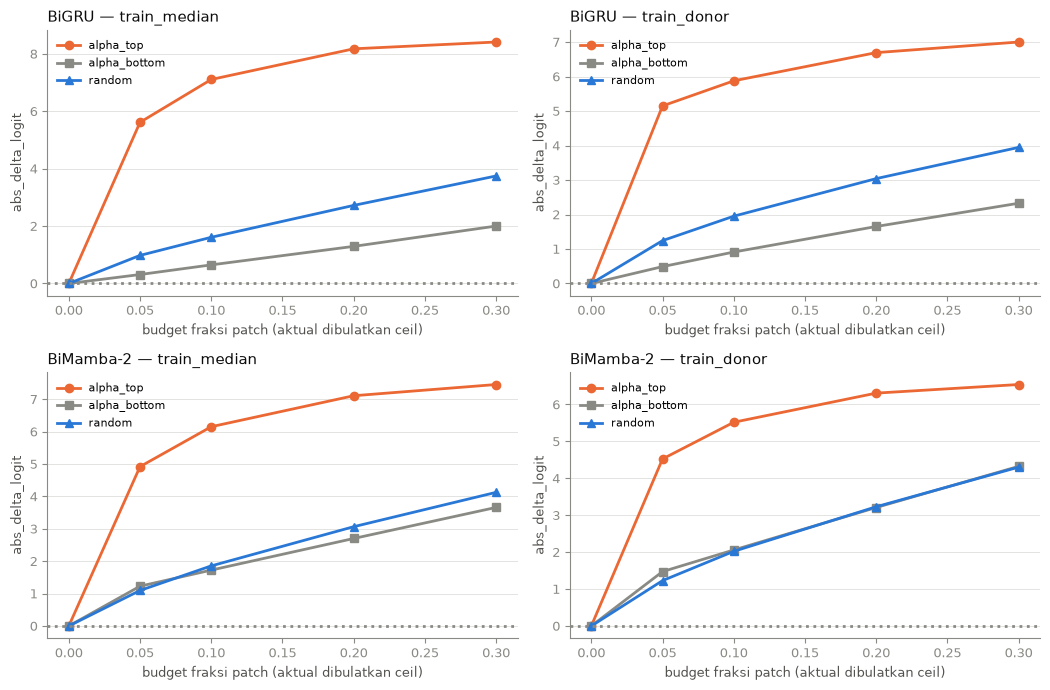

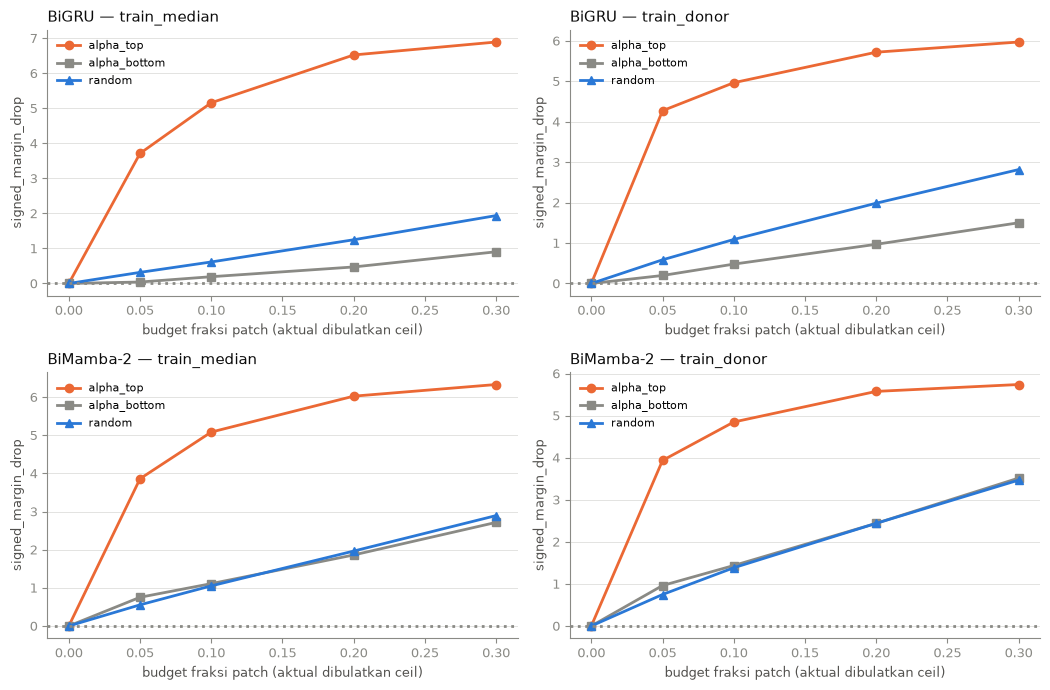

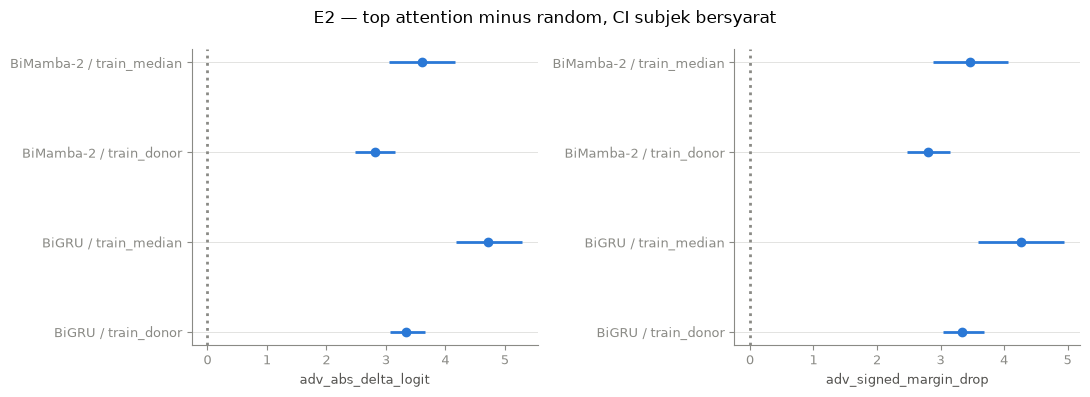

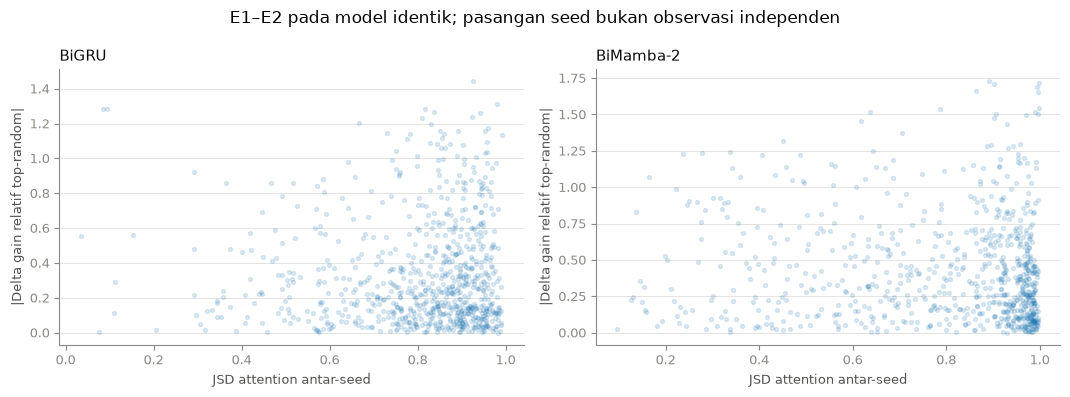

In [8]:
def savefig(fig,name):
    fig.savefig(FIG / (name+".png"),dpi=180,bbox_inches="tight")
    fig.savefig(FIG / (name+".pdf"),bbox_inches="tight")
labels={"gru":"BiGRU","mamba2":"BiMamba-2"}
styles={"alpha_top":("#eb6834","o"),"alpha_bottom":("#8a8a85","s"),"random":("#2a78d6","^")}
subject_curve = curve_mean.groupby(["architecture","masker","ranking","subject","label","idx","requested_fraction"])[
    ["abs_delta_logit","signed_margin_drop"]].mean().reset_index()
subject_curve = subject_curve.groupby(["architecture","masker","ranking","subject","label","requested_fraction"])[
    ["abs_delta_logit","signed_margin_drop"]].mean().reset_index()
subject_curve.to_csv(OUT / "e2_subject_curves.csv",index=False)
population_curve = subject_curve.groupby(["architecture","masker","ranking","requested_fraction"])[
    ["abs_delta_logit","signed_margin_drop"]].mean().reset_index()
population_curve.to_csv(OUT / "e2_population_curves.csv",index=False)
for metric in ("abs_delta_logit","signed_margin_drop"):
    fig,axes=plt.subplots(2,2,figsize=(10.6,7),squeeze=False)
    for i,arm in enumerate(ARMS):
        for j,masker in enumerate(("train_median","train_donor")):
            ax=axes[i,j]
            for ranking,(color,marker) in styles.items():
                d=population_curve[(population_curve.architecture==arm)&(population_curve.masker==masker)&
                                   (population_curve.ranking==ranking)].sort_values("requested_fraction")
                ax.plot(np.r_[0,d.requested_fraction],np.r_[0,d[metric]],color=color,marker=marker,label=ranking)
            ax.set_title(labels[arm]+" — "+masker,loc="left")
            ax.set_xlabel("budget fraksi patch (aktual dibulatkan ceil)"); ax.set_ylabel(metric)
            ax.axhline(0,color="#8a8a85",ls=":"); ax.legend(fontsize=8); rapikan(ax)
    fig.tight_layout(); savefig(fig,"e2_curves_"+metric); plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,metric in zip(axes,("adv_abs_delta_logit","adv_signed_margin_drop")):
    selected=e2_ci[e2_ci.metric==metric].reset_index(drop=True)
    for i,row in selected.iterrows():
        ax.hlines(i,row.ci_low,row.ci_high,color="#2a78d6",lw=2)
        ax.plot(row.estimate,i,"o",color="#2a78d6")
    ax.set_yticks(range(len(selected)),[labels[r.architecture]+" / "+r.masker for r in selected.itertuples()])
    ax.axvline(0,color="#8a8a85",ls=":");ax.set_xlabel(metric);rapikan(ax)
fig.suptitle("E2 — top attention minus random, CI subjek bersyarat")
fig.tight_layout();savefig(fig,"e2_contrast_ci");plt.show()
fig,axes=plt.subplots(1,2,figsize=(10.8,4))
for ax,arm in zip(axes,ARMS):
    d=joint[(joint.architecture==arm)&(joint.masker=="train_median")]
    ax.scatter(d.js_divergence,d.abs_delta_relative_gain,s=8,alpha=.15,rasterized=True)
    ax.set_xlabel("JSD attention antar-seed");ax.set_ylabel("|Delta gain relatif top-random|")
    ax.set_title(labels[arm],loc="left");rapikan(ax)
fig.suptitle("E1–E2 pada model identik; pasangan seed bukan observasi independen")
fig.tight_layout();savefig(fig,"joint_e1_e2_continuous");plt.show()

## 7. Penyelesaian dan batas klaim

E2 dapat mendukung hasil positif, negatif, atau belum menentukan. Jika kedua peta
berbeda tetapi sama-sama mengidentifikasi input berpengaruh, variasi peta dapat
tetap kompatibel dengan faithfulness. Jika contrast attention terhadap acak rendah
atau berubah menurut masker, batasi klaim pada pengujian dan masker tersebut.
Signed support negatif tidak sama dengan tidak berpengaruh.

Jangan menyebut hasil sebagai validasi fisiologis, atau menjadikan CI yang memuat
nol bukti ekuivalensi. Ketergantungan fold dan training tidak dicakup oleh bootstrap
OOF tetap. E3 diperlukan untuk klaim perturbasi input kecil; notebook ini tidak
menguji E3. Hasil dan checkpoint baru tidak mengganti bukti/angka lama.


In [9]:
inventory["sha256_after"]=[file_sha256(ROOT / p) for p in inventory.path]
inventory["unchanged"]=inventory.sha256_before==inventory.sha256_after
inventory.to_csv(OUT / "input_inventory.csv",index=False)
if not inventory.unchanged.all():
    manifest["completion_status"]="invalid_inputs_changed"
    (OUT / "analysis_manifest.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")
    raise RuntimeError("input/sumber berubah selama run; jangan gunakan hasil ini")
manifest.update(completion_status="complete",completed_utc=datetime.now(timezone.utc).isoformat(),
    training_performed=bool(model_inventory.trained_now.any()),
    models_trained_now=int(model_inventory.trained_now.sum()),
    tables=sorted(p.name for p in OUT.glob("*.csv")),figures=sorted(p.name for p in FIG.iterdir()))
(OUT / "analysis_manifest.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")
print("Selesai:",OUT)
print("Checkpoint:",ROOT / "checkpoints/e2")
print("Analisis tambahan eksploratori; E1/E2 model baru, tanpa perubahan preregistrasi/manuskrip lama.")

Selesai: /home/agribychaniago/Python Projects/Skripsi/results/e2/20261012T050124548170Z
Checkpoint: /home/agribychaniago/Python Projects/Skripsi/checkpoints/e2
Analisis tambahan eksploratori; E1/E2 model baru, tanpa perubahan preregistrasi/manuskrip lama.
